# XGBoost model: heart disease risk from BRFSS 2022

Target is `HadHeartAttack` (Yes/No), roughly 5-6% positive. This notebook trains an XGBoost classifier, tunes it, and evaluates on the held-out test set with ROC-AUC, PR-AUC, F1, precision, recall and a confusion matrix.

Plan:
1. load, drop rows with no label, split 60/20/20 (same seed and stratification as the EDA notebook)
2. encode features, fit a plain baseline
3. add a few engineered features and see if they help
4. tune hyperparameters with cross-validation on the training set
5. pick a threshold on validation, report once on test

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve,
                             roc_curve)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)

SEED = 42
DATA_PATH = "../Data/heart_2022_with_nans.csv"
TARGET = "HadHeartAttack"

### 1. Load and split

In [3]:
with open(DATA_PATH, encoding="utf-8") as f:
    if f.readline().startswith("version https://git-lfs"):
        raise RuntimeError("Data file is a Git LFS pointer. Run `git lfs pull` first.")

df = pd.read_csv(DATA_PATH)
print("raw shape:", df.shape)

# rows with no label can't be used for training or scoring
df = df[df[TARGET].notna()].reset_index(drop=True)
y = (df[TARGET] == "Yes").astype(int)
X_raw = df.drop(columns=[TARGET])

print("after dropping unlabeled:", df.shape)
print(f"positive rate: {y.mean():.2%}")

raw shape: (445132, 40)
after dropping unlabeled: (442067, 40)
positive rate: 5.68%


In [4]:
# 60 / 20 / 20, stratified so the positive rate matches in every split
X_tmp, X_test_raw, y_tmp, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<6}{len(part):>8,} rows   positive rate {part.mean():.2%}")

train  265,239 rows   positive rate 5.68%
val     88,414 rows   positive rate 5.68%
test    88,414 rows   positive rate 5.68%


### 2. Encoding and missing values

XGBoost handles `NaN` natively (it learns which branch missing values should take), so I'm not imputing anything. That also keeps the "was it missing" signal, which can matter in survey data where skipped questions aren't random.

- Yes/No columns become 1/0, with missing left as `NaN`
- ordinal columns (general health, checkup, smoking, ...) get an integer order
- age category becomes the lower bound of the bracket (e.g. "Age 65 to 69" -> 65)
- the four unordered categoricals go in as pandas `category` dtype, using levels from the training set only
- `State` is dropped: 54 levels, little signal expected, and it just adds noise

In [5]:
YES_NO = ["PhysicalActivities", "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer",
          "HadCOPD", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis",
          "DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
          "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands",
          "ChestScan", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12",
          "PneumoVaxEver", "HighRiskLastYear"]

ORDINAL = {
    "GeneralHealth": {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4},
    "RemovedTeeth": {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3},
    "LastCheckupTime": {
        "Within past year (anytime less than 12 months ago)": 0,
        "Within past 2 years (1 year but less than 2 years ago)": 1,
        "Within past 5 years (2 years but less than 5 years ago)": 2,
        "5 or more years ago": 3},
    "SmokerStatus": {
        "Never smoked": 0, "Former smoker": 1,
        "Current smoker - now smokes some days": 2,
        "Current smoker - now smokes every day": 3},
    "ECigaretteUsage": {
        "Never used e-cigarettes in my entire life": 0, "Not at all (right now)": 1,
        "Use them some days": 2, "Use them every day": 3},
}

CAT_COLS = ["HadDiabetes", "RaceEthnicityCategory", "TetanusLast10Tdap", "CovidPos"]

CHRONIC = ["HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
           "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis"]
DISABILITY = ["DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
              "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands"]


def encode(raw, engineer=False):
    X = raw.drop(columns=["State"]).copy()

    for c in YES_NO:
        X[c] = raw[c].map({"Yes": 1.0, "No": 0.0})
    X["Sex"] = raw["Sex"].map({"Male": 1.0, "Female": 0.0})
    for c, order in ORDINAL.items():
        X[c] = raw[c].map(order)
    X["AgeCategory"] = raw["AgeCategory"].str.extract(r"(\d+)", expand=False).astype(float)

    if engineer:
        # BMI is missing for some rows where height and weight are both there
        X["BMI"] = raw["BMI"].fillna(raw["WeightInKilograms"] / raw["HeightInMeters"] ** 2)
        X["chronic_count"] = X[CHRONIC].sum(axis=1)
        X["diabetes_yes"] = (raw["HadDiabetes"] == "Yes").astype(float)
        X["disability_count"] = X[DISABILITY].sum(axis=1)
        X["n_missing"] = raw.isna().sum(axis=1)
    return X


def set_categories(X, levels=None):
    X = X.copy()
    if levels is None:
        levels = {c: sorted(X[c].dropna().unique()) for c in CAT_COLS}
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c], categories=levels[c])
    return X, levels

In [6]:
def build(engineer):
    tr, levels = set_categories(encode(X_train_raw, engineer))
    va, _ = set_categories(encode(X_val_raw, engineer), levels)
    te, _ = set_categories(encode(X_test_raw, engineer), levels)
    return tr, va, te

X_train_b, X_val_b, X_test_b = build(engineer=False)   # encoding only
X_train, X_val, X_test = build(engineer=True)          # encoding + extra features

print(X_train_b.shape, "->", X_train.shape)
X_train.isna().mean().sort_values(ascending=False).head(8).round(3)

(265239, 38) -> (265239, 42)


TetanusLast10Tdap    0.185
PneumoVaxEver        0.172
HIVTesting           0.148
ChestScan            0.125
CovidPos             0.113
HighRiskLastYear     0.113
FluVaxLast12         0.105
AlcoholDrinkers      0.104
dtype: float64

### 3. Baseline and feature check

Default-ish XGBoost, with and without the engineered columns, scored on validation. Imbalance is handled with `scale_pos_weight` here only so the model pays attention to the positives; ROC-AUC and PR-AUC only care about ranking, and the decision threshold gets picked separately later.

In [7]:
def scores(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, p),
            "PR-AUC": average_precision_score(y_true, p),
            "F1": f1_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred)}

spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.1f}")

base_kwargs = dict(tree_method="hist", enable_categorical=True, eval_metric="auc",
                   random_state=SEED, n_jobs=-1)

rows = {}
for label, (Xtr, Xva) in {"baseline (encoded only)": (X_train_b, X_val_b),
                          "+ engineered features": (X_train, X_val)}.items():
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                          scale_pos_weight=spw, **base_kwargs)
    m.fit(Xtr, y_train)
    rows[label] = scores(y_val, m.predict_proba(Xva)[:, 1])

pd.DataFrame(rows).T.round(4)

scale_pos_weight = 16.6


,ROC-AUC,PR-AUC,F1,Precision,Recall
baseline (encoded only),0.8902,0.4239,0.3403,0.2169,0.7885
+ engineered features,0.8905,0.4269,0.3387,0.2156,0.7899


Engineered features that don't move the validation numbers get dropped rather than kept for the sake of it, so I'm picking whichever set scored better on ROC-AUC for the tuning step.

In [8]:
auc_base = rows["baseline (encoded only)"]["ROC-AUC"]
auc_fe = rows["+ engineered features"]["ROC-AUC"]

if auc_fe >= auc_base:
    X_train_use, X_val_use, X_test_use = X_train, X_val, X_test
    print("using engineered features")
else:
    X_train_use, X_val_use, X_test_use = X_train_b, X_val_b, X_test_b
    print("using encoded-only features")

using engineered features


### 4. Hyperparameter tuning

Randomized search, 3-fold stratified CV on the training split only, scored on ROC-AUC. The validation set stays out of this so it can still be used for early stopping and threshold choice afterwards. On a laptop this takes a while (roughly 10-20 minutes); lower `n_iter` if you just want to check the notebook runs.

In [9]:
param_dist = {
    "max_depth": randint(3, 8),
    "learning_rate": loguniform(0.02, 0.15),
    "n_estimators": randint(200, 700),
    "min_child_weight": randint(1, 20),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "gamma": uniform(0, 2),
    "reg_lambda": loguniform(0.5, 20),
    "reg_alpha": loguniform(1e-3, 5),
}

search = RandomizedSearchCV(
    xgb.XGBClassifier(**base_kwargs),
    param_distributions=param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    random_state=SEED,
    verbose=1,
    n_jobs=1,
)
search.fit(X_train_use, y_train)

print(f"best CV ROC-AUC: {search.best_score_:.4f}")
best_params = search.best_params_
pd.Series(best_params).round(4)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
best CV ROC-AUC: 0.8931


colsample_bytree      0.6374
gamma                 1.1225
learning_rate         0.0433
max_depth             5.0000
min_child_weight      1.0000
n_estimators        204.0000
reg_alpha             0.1192
reg_lambda            8.5922
subsample             0.7975
dtype: float64

In [10]:
# a quick look at the top few configurations
cv = pd.DataFrame(search.cv_results_)
cols = ["mean_test_score", "std_test_score"] + [f"param_{k}" for k in ["max_depth", "learning_rate", "n_estimators", "min_child_weight"]]
cv.sort_values("mean_test_score", ascending=False)[cols].head(5).round(4)

,mean_test_score,std_test_score,param_max_depth,param_learning_rate,param_n_estimators,param_min_child_weight
11,0.8931,0.0025,5,0.043263,204,1
2,0.8930,0.0023,3,0.047754,675,10
1,0.8929,0.0024,4,0.020847,613,12
12,0.8926,0.0025,7,0.021051,262,19
10,0.8925,0.0025,3,0.049468,606,16


### 5. Final model

Refit with the best parameters. The number of trees is left high and early stopping on the validation set picks where to stop.

In [11]:
final_params = {k: v for k, v in best_params.items() if k != "n_estimators"}

final = xgb.XGBClassifier(n_estimators=2000, early_stopping_rounds=50,
                          **final_params, **base_kwargs)
final.fit(X_train_use, y_train, eval_set=[(X_val_use, y_val)], verbose=False)

print("trees used:", final.best_iteration + 1)

p_val = final.predict_proba(X_val_use)[:, 1]
print(f"validation ROC-AUC: {roc_auc_score(y_val, p_val):.4f}")
print(f"validation PR-AUC:  {average_precision_score(y_val, p_val):.4f}")

trees used: 245
validation ROC-AUC: 0.8912
validation PR-AUC:  0.4304


### Choosing a threshold

0.5 is a bad cutoff when only ~6% of rows are positive. I pick the threshold that maximizes F1 on the validation set. If missing a case is costlier than a false alarm, a lower threshold is easy to justify; the table in the next section shows the tradeoff.

In [12]:
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"threshold chosen on validation: {best_thr:.3f}  (val F1 = {f1s.max():.4f})")

threshold chosen on validation: 0.236  (val F1 = 0.4870)


### 6. Test set results

In [13]:
p_test = final.predict_proba(X_test_use)[:, 1]
test_pred = (p_test >= best_thr).astype(int)

summary = scores(y_test, p_test, best_thr)
print(f"Test ROC-AUC  : {summary['ROC-AUC']:.4f}")
print(f"Test PR-AUC   : {summary['PR-AUC']:.4f}")
print(f"Test F1       : {summary['F1']:.4f}")
print(f"Test Precision: {summary['Precision']:.4f}")
print(f"Test Recall   : {summary['Recall']:.4f}")
print(f"(threshold = {best_thr:.3f})")

Test ROC-AUC  : 0.8904
Test PR-AUC   : 0.4318
Test F1       : 0.4850
Test Precision: 0.4462
Test Recall   : 0.5313
(threshold = 0.236)


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["No", "Yes"]).plot(ax=axes[0], cmap="Blues", colorbar=False,
                                                          values_format=",")
axes[0].set_title(f"Confusion matrix (threshold {best_thr:.2f})")

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f"AUC = {summary['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rc, pr, label=f"AP = {summary['PR-AUC']:.3f}")
axes[2].axhline(y_test.mean(), ls="--", color="gray", label="no-skill")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-recall curve"); axes[2].legend()

plt.tight_layout()
plt.show()

<Figure size 1600x450 with 3 Axes>

In [15]:
# precision / recall at a few operating points
ops = {}
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, round(float(best_thr), 3)]:
    pred = (p_test >= t).astype(int)
    ops[t] = {"Precision": precision_score(y_test, pred, zero_division=0),
              "Recall": recall_score(y_test, pred),
              "F1": f1_score(y_test, pred),
              "Flagged %": pred.mean() * 100}
pd.DataFrame(ops).T.sort_index().round(3)

,Precision,Recall,F1,Flagged %
0.050,0.195,0.805,0.314,23.407
0.100,0.305,0.665,0.418,12.391
0.150,0.382,0.595,0.465,8.855
0.200,0.426,0.554,0.482,7.388
0.236,0.446,0.531,0.485,6.759
0.300,0.478,0.487,0.483,5.793
0.500,0.602,0.255,0.358,2.405


### 7. What the model is using

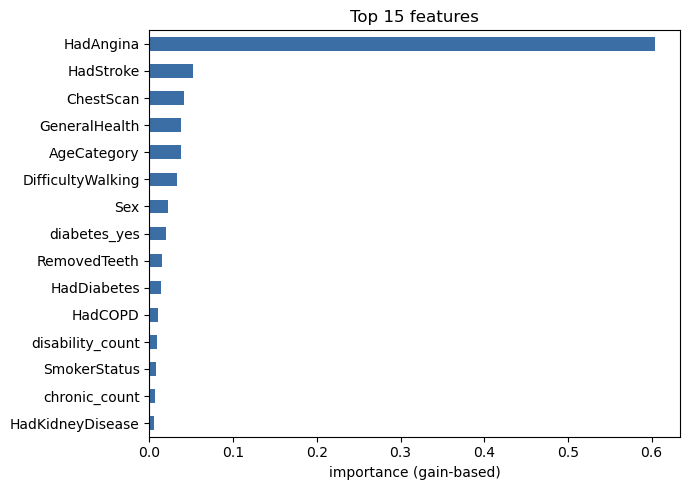

In [ ]:
imp = pd.Series(final.feature_importances_, index=X_train_use.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), color="#3b6ea5")
plt.xlabel("importance (gain-based)")
plt.title("Top 15 features")
plt.tight_layout()
plt.show()

## Notes

- `HadAngina` and the age / general health variables will likely sit near the top. Angina is closely tied to heart attack history, so part of the signal here is "other heart problems", not lifestyle.
- All of this is self-reported survey data about a past diagnosis. It says nothing about future risk and isn't meant for clinical use.
- Everything tuned or chosen (feature set, hyperparameters, early stopping, threshold) used train/validation data only. The test set was scored once at the end.
- Not done here: subgroup fairness checks (race, sex, age, income) and SHAP, both listed in the project overview for the final milestone.